In [1]:
## Atown's stuff
import os
import sys
sys.path.append("..")
from globalsC2 import *

from PickleLite import *

# import MakeSpectra as MS
print(COMP2PATH)

CF4HOME: /Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4
COMP2PATH: /Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2
Welcome to JupyROOT 6.27/01
/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2


In [ ]:
# Example usage (uncomment and set COMP2PATH if not already in scope):
save_dir = os.path.join(COMP2PATH, "DataAnalysis", "saved_spectra")

## opening multiple in one file
co_bare = load_snap_list(os.path.join(save_dir, "rc_Co_bare_source.snap.pkl"))
print(type(co_bare[0]))
print(f"Loaded {len(co_bare)} Co bare LiteRun objects. First IDs:", [lr.id for lr in co_bare[:3]])

# Optional: tiny loader example which also works
# with open(os.path.join(save_dir, "rc_Co_bare_source.snap.pkl"), "rb") as f:
#   co_bare_loaded = pickle.load(f)
#   print(f"Loaded {len(co_bare_loaded)} Co bare snapshots. First IDs:", [d["id"] for d in co_bare_loaded[:3]])
#   print(type(co_bare_loaded[0]))

<class 'PickleLite.LiteRun'>
Loaded 5 Co bare LiteRun objects. First IDs: ['202203031411', '202203031118', '202203031135']


---
### Load saved spectra and quick comparisons

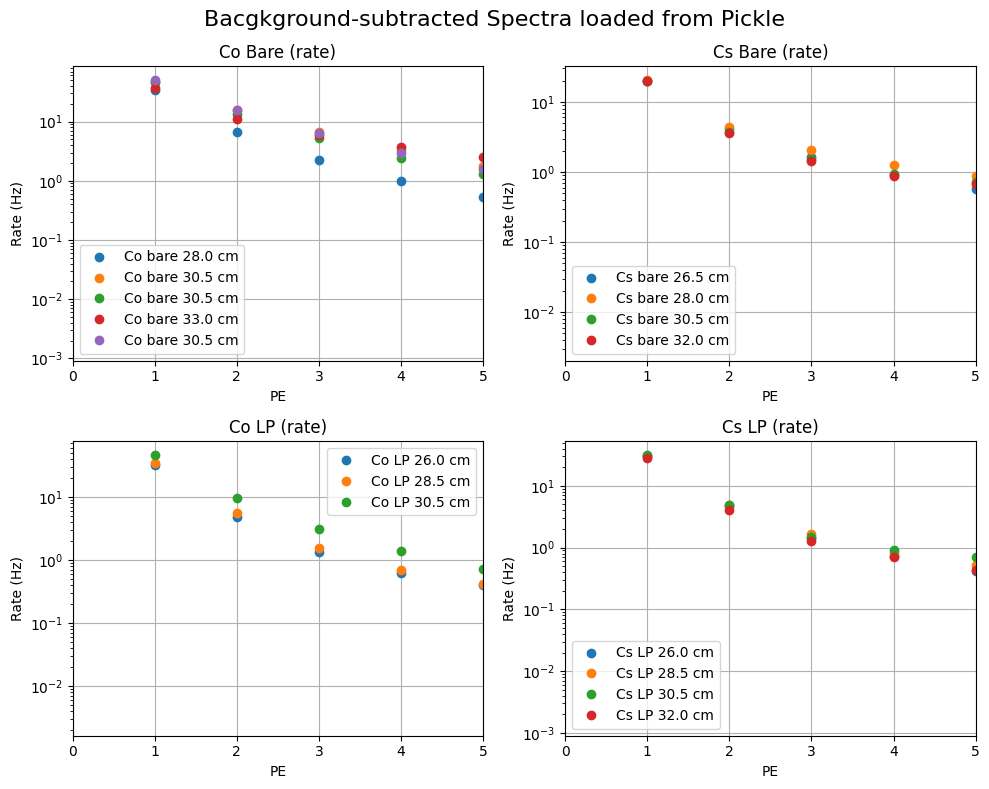

In [9]:
save_dir = os.path.join(COMP2PATH, "DataAnalysis", "saved_spectra")

co_bare = load_snap_list(os.path.join(save_dir, "rc_Co_bare_source.snap.pkl"))
cs_bare = load_snap_list(os.path.join(save_dir, "rc_Cs_bare_source.snap.pkl"))
co_lp = load_snap_list(os.path.join(save_dir, "rc_Co_LP_source.snap.pkl"))
cs_lp = load_snap_list(os.path.join(save_dir, "rc_Cs_LP_source.snap.pkl"))

# Plot one example per category
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for lr in co_bare:
  lr.mpl_errorbar(axes[0,0], use_bkgsub=False, label=f"Co bare {lr.height} cm")

axes[0,0].set_yscale('log'); axes[0,0].set_title("Co Bare (rate)"); axes[0,0].legend(); axes[0,0].grid(True)

for lr in cs_bare:
  lr.mpl_errorbar(axes[0,1], use_bkgsub=False, label=f"Cs bare {lr.height} cm")
axes[0,1].set_yscale('log'); axes[0,1].set_title("Cs Bare (rate)"); axes[0,1].legend(); axes[0,1].grid(True)

for lr in co_lp:
  lr.mpl_errorbar(axes[1,0], use_bkgsub=False, label=f"Co LP {lr.height} cm")
axes[1,0].set_yscale('log'); axes[1,0].set_title("Co LP (rate)"); axes[1,0].legend(); axes[1,0].grid(True)

for lr in cs_lp:
  lr.mpl_errorbar(axes[1,1], use_bkgsub=False, label=f"Cs LP {lr.height} cm")
axes[1,1].set_yscale('log'); axes[1,1].set_title("Cs LP (rate)"); axes[1,1].legend(); axes[1,1].grid(True)

for ax in axes.flat:
  ax.set_xlabel("PE"); ax.set_ylabel("Rate (Hz)")
  ax.set_xlim(0, 5)

fig.suptitle("Bacgkground-subtracted Spectra loaded from Pickle", fontsize=16)
plt.tight_layout(); plt.show()

In [8]:
import math
factorN = 100
Func_ScaleN = lambda ly, top:  int(math.ceil(1e6 * (0.5 + 0.5 * top / ly)/ factorN)) * factorN  # scale nbeam with ly

Func_ScaleN(1, 4)

2500000